# Diabetes Prevention Model
### CPSC 483 – Introduction to Machine Learning
**Phase 2: Exploratory Data Analysis**

**Author:** David Ulloa

---

## 1. Introduction
This notebook aims to examine the Pima Indians Diabetes dataset to uncover any issues present in the data, how the features are distributed, and how they relate to the outcome of developing diabetes to ultimately inform how to preprocess the data for building any machine learning models.

## 2. Library Imports

- **Pandas:** Dataset manipulation and inspection.
- **NumPy:** Numerical operations and missing values.
- **Plotnine:** Data visualization using Grammar of Graphics.
- **Scikit-learn:** Preprocessing and train/test splitting.

In [2]:
#Install library dependecies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from plotnine import *

## 3. Dataset Loading
Loading the data from within the `Datasets` folder

There are 768 rows in the dataset

The dataset has one binary target variable called `HasDiabetes`

There are eight predictor variables

To check what the data looks like, we will be showing the first five rows

In [3]:
#Import the dataset
df = pd.read_csv(
    "Datasets/pima-indians-diabetes-resampled.csv"
)

In [4]:
#gives a quick overview of the dataset
df.head()

,Preg,Glucose,BP,Skin,Insulin,BMI,Pedigree,Age,HasDiabetes
0,2,157,74,35,440,39.4,0.134,30,0
1,7,159,64,0,0,27.4,0.294,40,0
2,7,83,78,26,71,29.3,0.767,36,0
3,0,124,56,13,105,21.8,0.452,21,0
4,5,99,54,28,83,34.0,0.499,30,0


## 4. Data Inspection

In this section, we will assess the data quality by performing the following checks:

1. Missing values

2. Duplicate rows

3. Summary statistics

4. Invalid zero values from a medical perspective

These checks will uncover problems that need to be solved before using the data to train any machine learning models.

In [5]:
# Returnrs missing values in the dataset, duplicate rows, and summary statistics
print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nSummary Statistics:")
display(df.describe())


Missing Values:
Preg           0
Glucose        0
BP             0
Skin           0
Insulin        0
BMI            0
Pedigree       0
Age            0
HasDiabetes    0
dtype: int64

Duplicate Rows:
0

Summary Statistics:


,Preg,Glucose,BP,Skin,Insulin,BMI,Pedigree,Age,HasDiabetes
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [6]:
# Returns the count of medically invalid zero values in specific columns
medical_columns = [
    "Glucose",
    "BP",
    "Skin",
    "Insulin",
    "BMI"
]

print("Medically invalid zero values:\n")

for col in medical_columns:
    count = (df[col] == 0).sum()
    percentage = (count / len(df)) * 100

    print(f"{col}: {count} ({percentage:.2f}%)")

Medically invalid zero values:

Glucose: 5 (0.65%)
BP: 35 (4.56%)
Skin: 227 (29.56%)
Insulin: 374 (48.70%)
BMI: 11 (1.43%)


### 4.1 Medically Invalid Zero Values

Several medical measurements contain zeros that are not
valid.

| Feature | Invalid Zeros | Percentage |
|---|---:|---:|
| Glucose | 5 | 0.65% |
| BP | 35 | 4.56% |
| Skin | 227 | 29.56% |
| Insulin | 374 | 48.70% |
| BMI | 11 | 1.43% |

In preprocessing, these will be considered as missing data.

As the variable with the most invalid zeros, insulin will need special attention during preprocessing.

## 5. Target Variable Analysis

The target variable, `HasDiabetes`, indicates whether an
observation is classified as having diabetes.

- **0:** No diabetes
- **1:** Diabetes

A bar chart is used to visualize the distribution of the
two outcome classes.

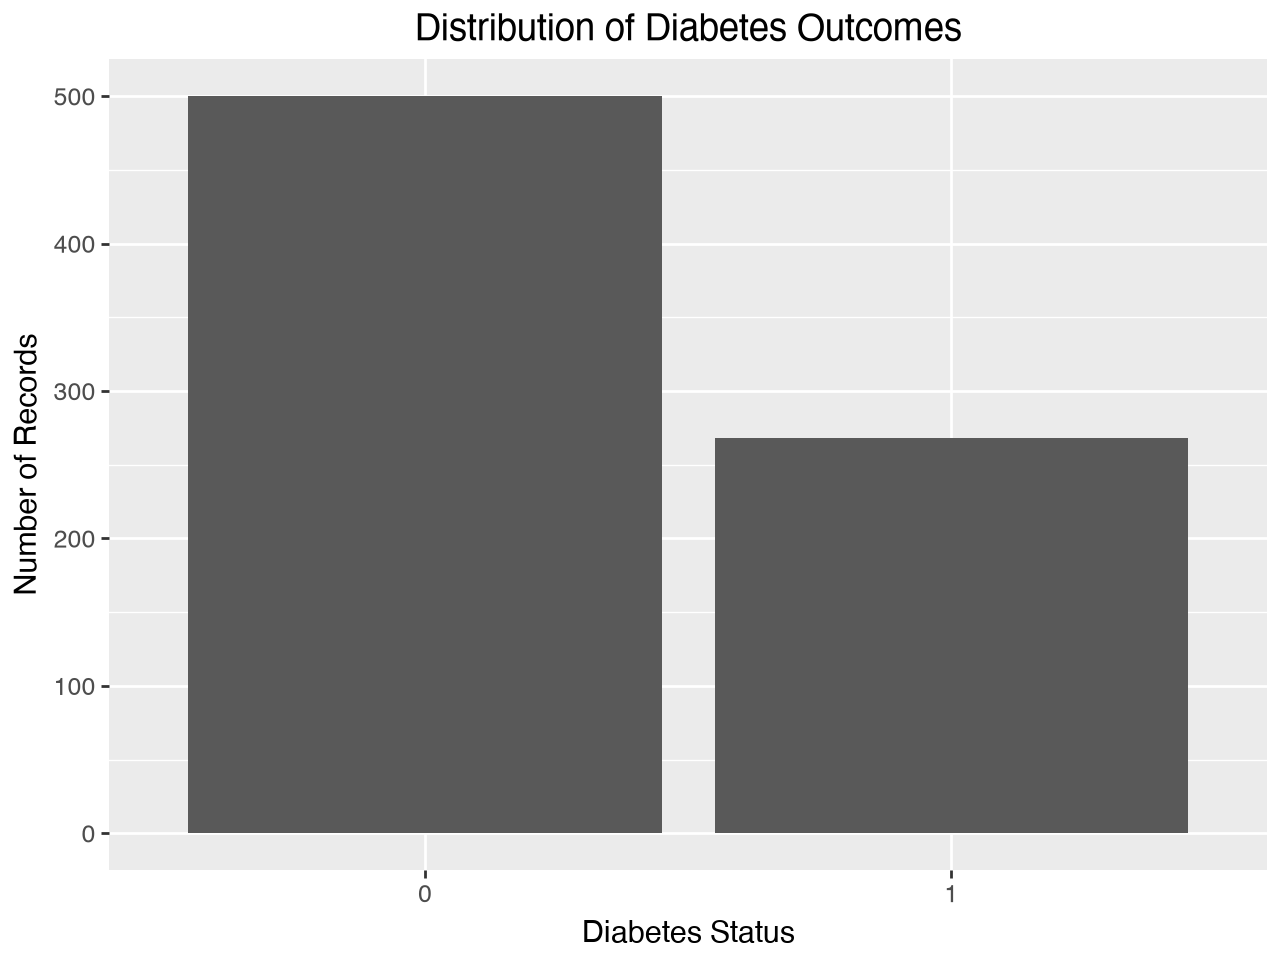

In [7]:
# Returns the distribution of the target variable "HasDiabetes"
ggplot(df, aes(x="factor(HasDiabetes)")) + \
    geom_bar() + \
    labs(
        title="Distribution of Diabetes Outcomes",
        x="Diabetes Status",
        y="Number of Records"
    )

### Interpretation

The dataset has:

- 500 observations (65.1%) that do *not* have diabetes

- 268 observations (34.9%) that *have* diabetes

There is a moderate degree of class imbalance in the target variable.

To ensure that the training and testing datasets have similar class distribution to the overall dataset, a stratified sampling approach will be used.

## 6. Feature Distribution Analysis

In this subsection, we analyze the distribution of each numerical predictor to look for outliers, unusual values, and skewness.

A visual analysis excludes zero values to prevent misleading data. These zero values are considered medically invalid.

In [13]:
#Prepares the dataset for exploratory data analysis (EDA) by replacing medically invalid zero values with NaN
df_eda = df.copy()

medical_columns = [
    "Glucose",
    "BP",
    "Skin",
    "Insulin",
    "BMI"
]

df_eda[medical_columns] = (
    df_eda[medical_columns].replace(0, np.nan)
)


/Users/davidulloa/Desktop/Fall '26/Intro to Machine Learning/CPSC-483-Project/.venv/lib/python3.12/site-packages/plotnine/layer.py:293: PlotnineWarning: stat_bin : Removed 5 rows containing non-finite values.


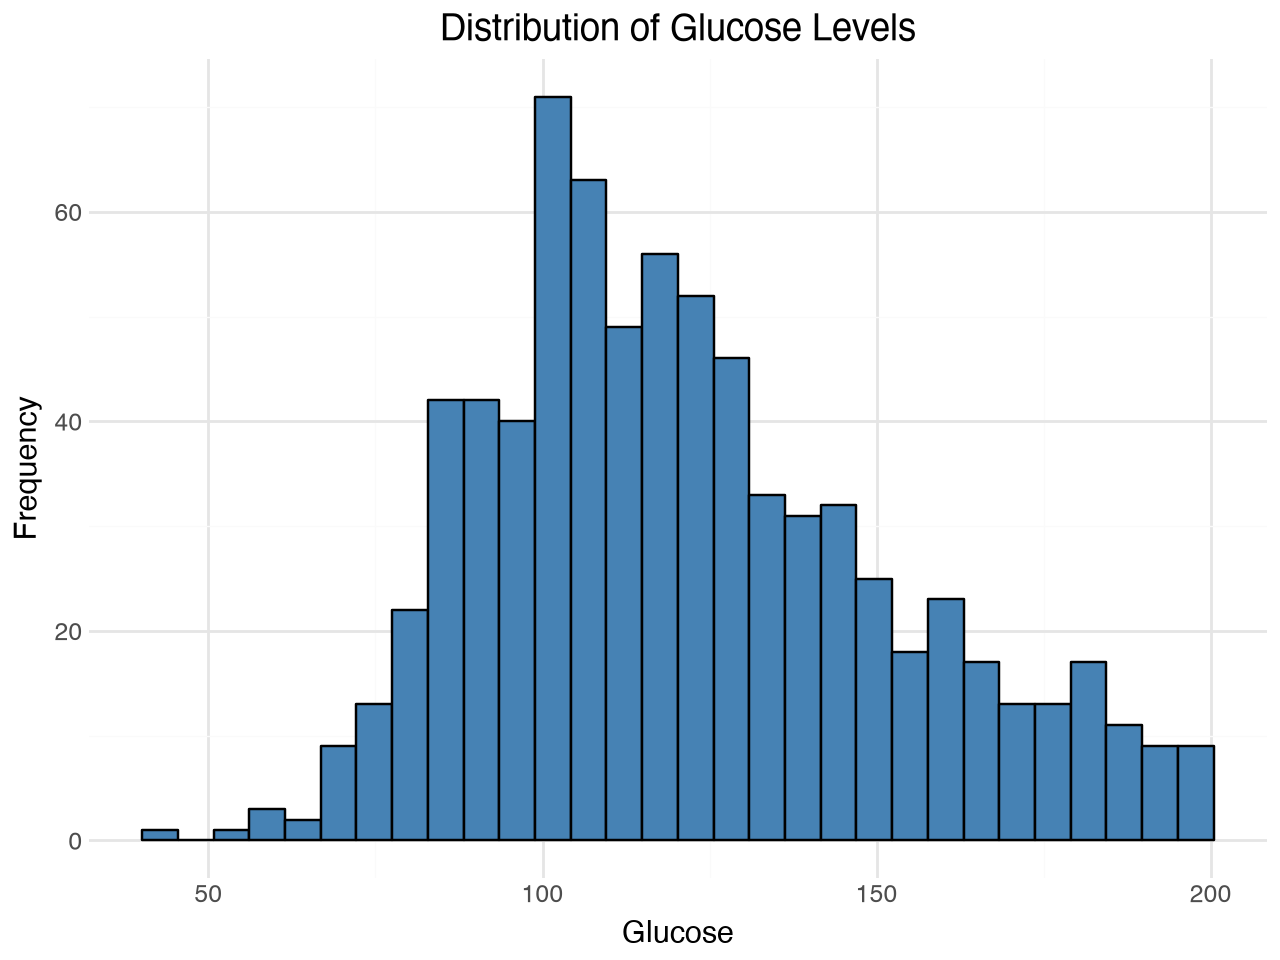

In [14]:
# Returns a histogram of the "Glucose" column in the dataset, showing the distribution of glucose levels
ggplot(df_eda, aes(x="Glucose")) + \
    geom_histogram(bins=30, fill="steelblue", color="black") + \
    labs(
        title="Distribution of Glucose Levels",
        x="Glucose",
        y="Frequency"
    ) + \
    theme_minimal()

/Users/davidulloa/Desktop/Fall '26/Intro to Machine Learning/CPSC-483-Project/.venv/lib/python3.12/site-packages/plotnine/layer.py:293: PlotnineWarning: stat_bin : Removed 11 rows containing non-finite values.


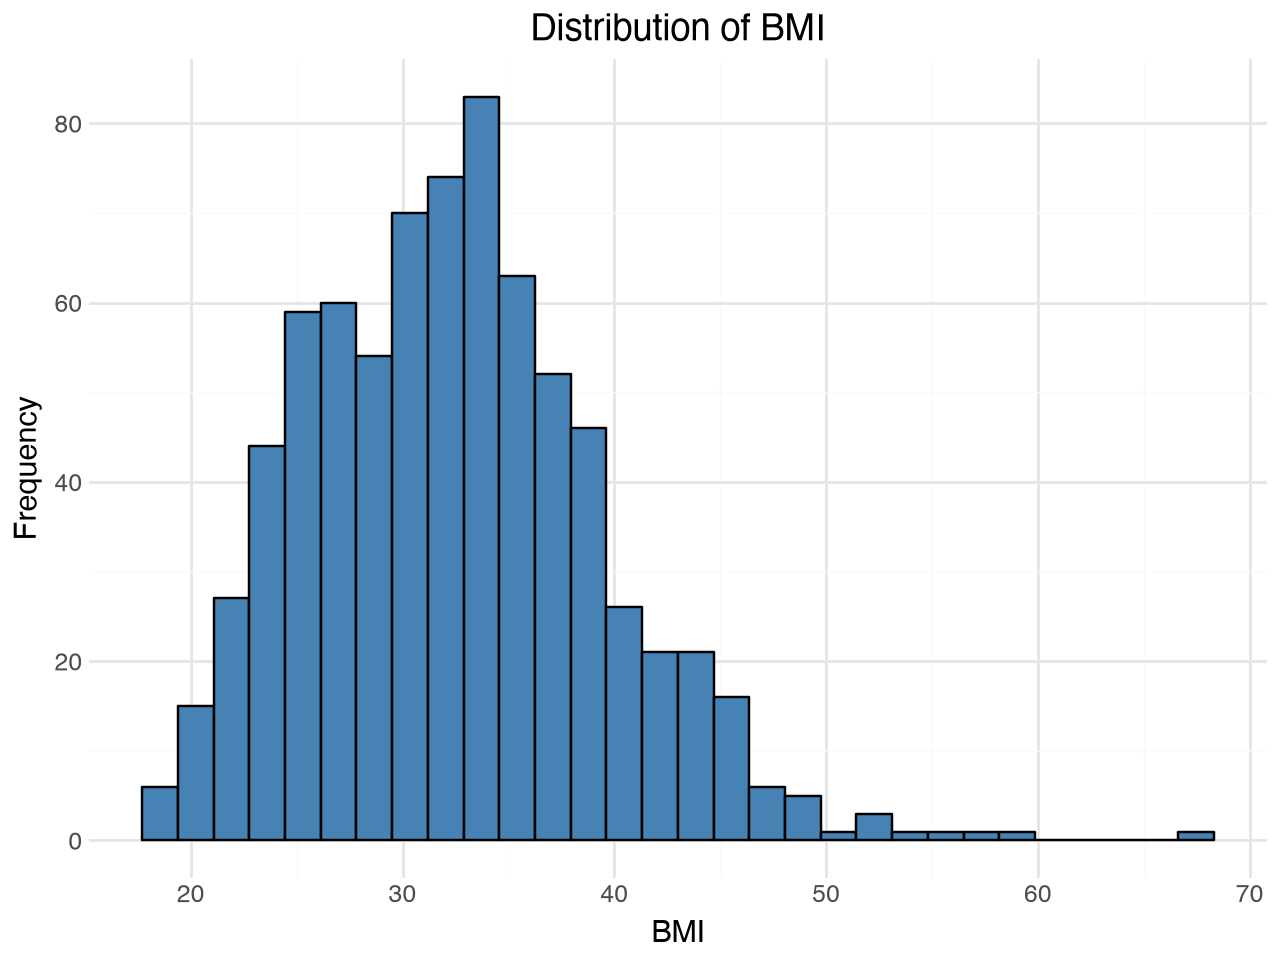

In [15]:
# Returns a histogram of the "BMI" column in the dataset, showing the distribution of BMI values
ggplot(df_eda, aes(x="BMI")) + \
    geom_histogram(bins=30, fill="steelblue", color="black") + \
    labs(
        title="Distribution of BMI",
        x="BMI",
        y="Frequency"
    ) + \
    theme_minimal()

/Users/davidulloa/Desktop/Fall '26/Intro to Machine Learning/CPSC-483-Project/.venv/lib/python3.12/site-packages/plotnine/layer.py:293: PlotnineWarning: stat_bin : Removed 374 rows containing non-finite values.


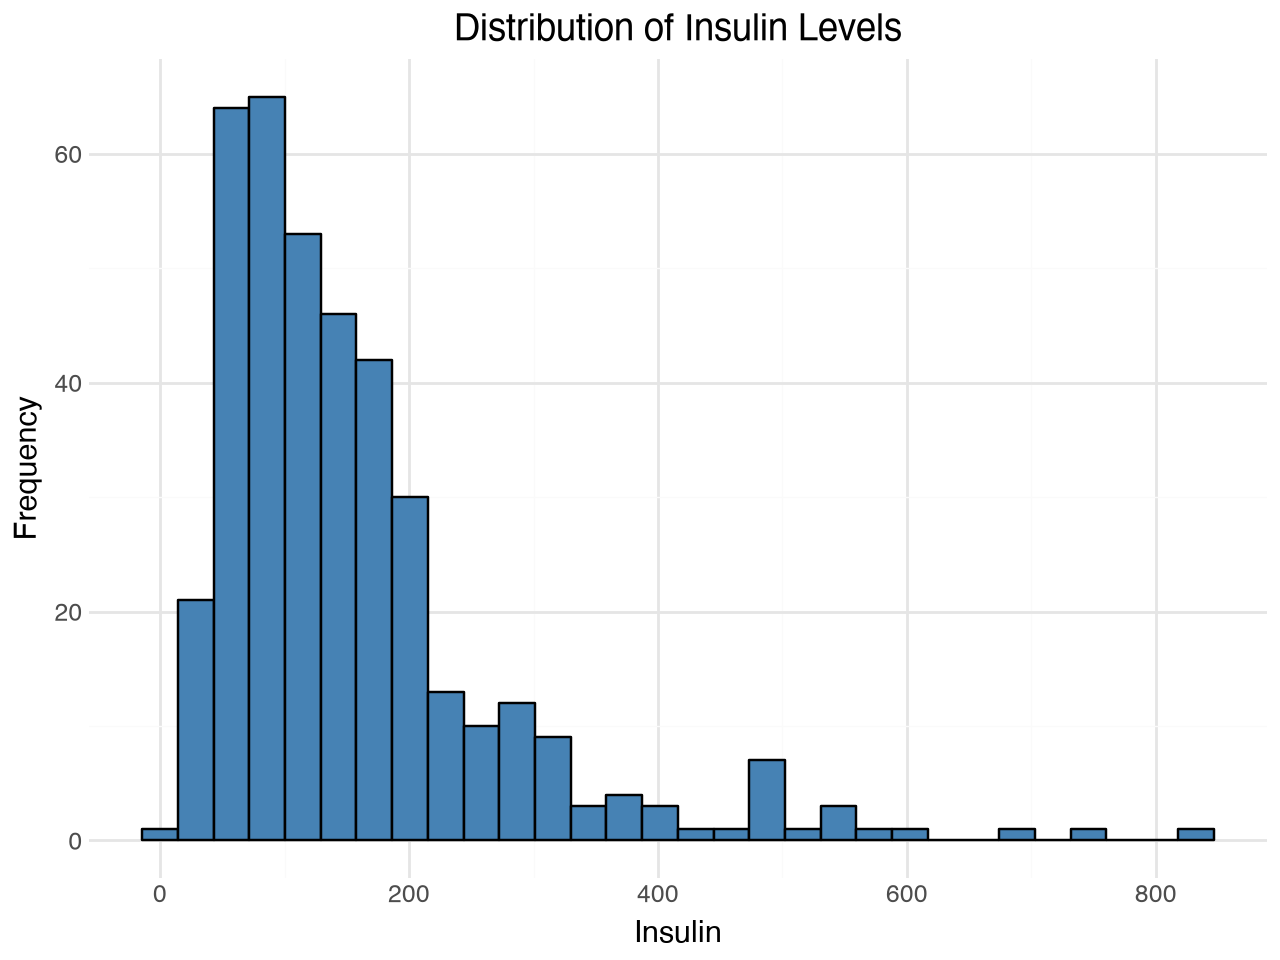

In [16]:
# Returns a histogram of the "Insulin" column in the dataset, showing the distribution of insulin levels
ggplot(df_eda, aes(x="Insulin")) + \
    geom_histogram(bins=30, fill="steelblue", color="black") + \
    labs(
        title="Distribution of Insulin Levels",
        x="Insulin",
        y="Frequency"
    ) + \
    theme_minimal()

/Users/davidulloa/Desktop/Fall '26/Intro to Machine Learning/CPSC-483-Project/.venv/lib/python3.12/site-packages/plotnine/layer.py:293: PlotnineWarning: stat_bin : Removed 652 rows containing non-finite values.


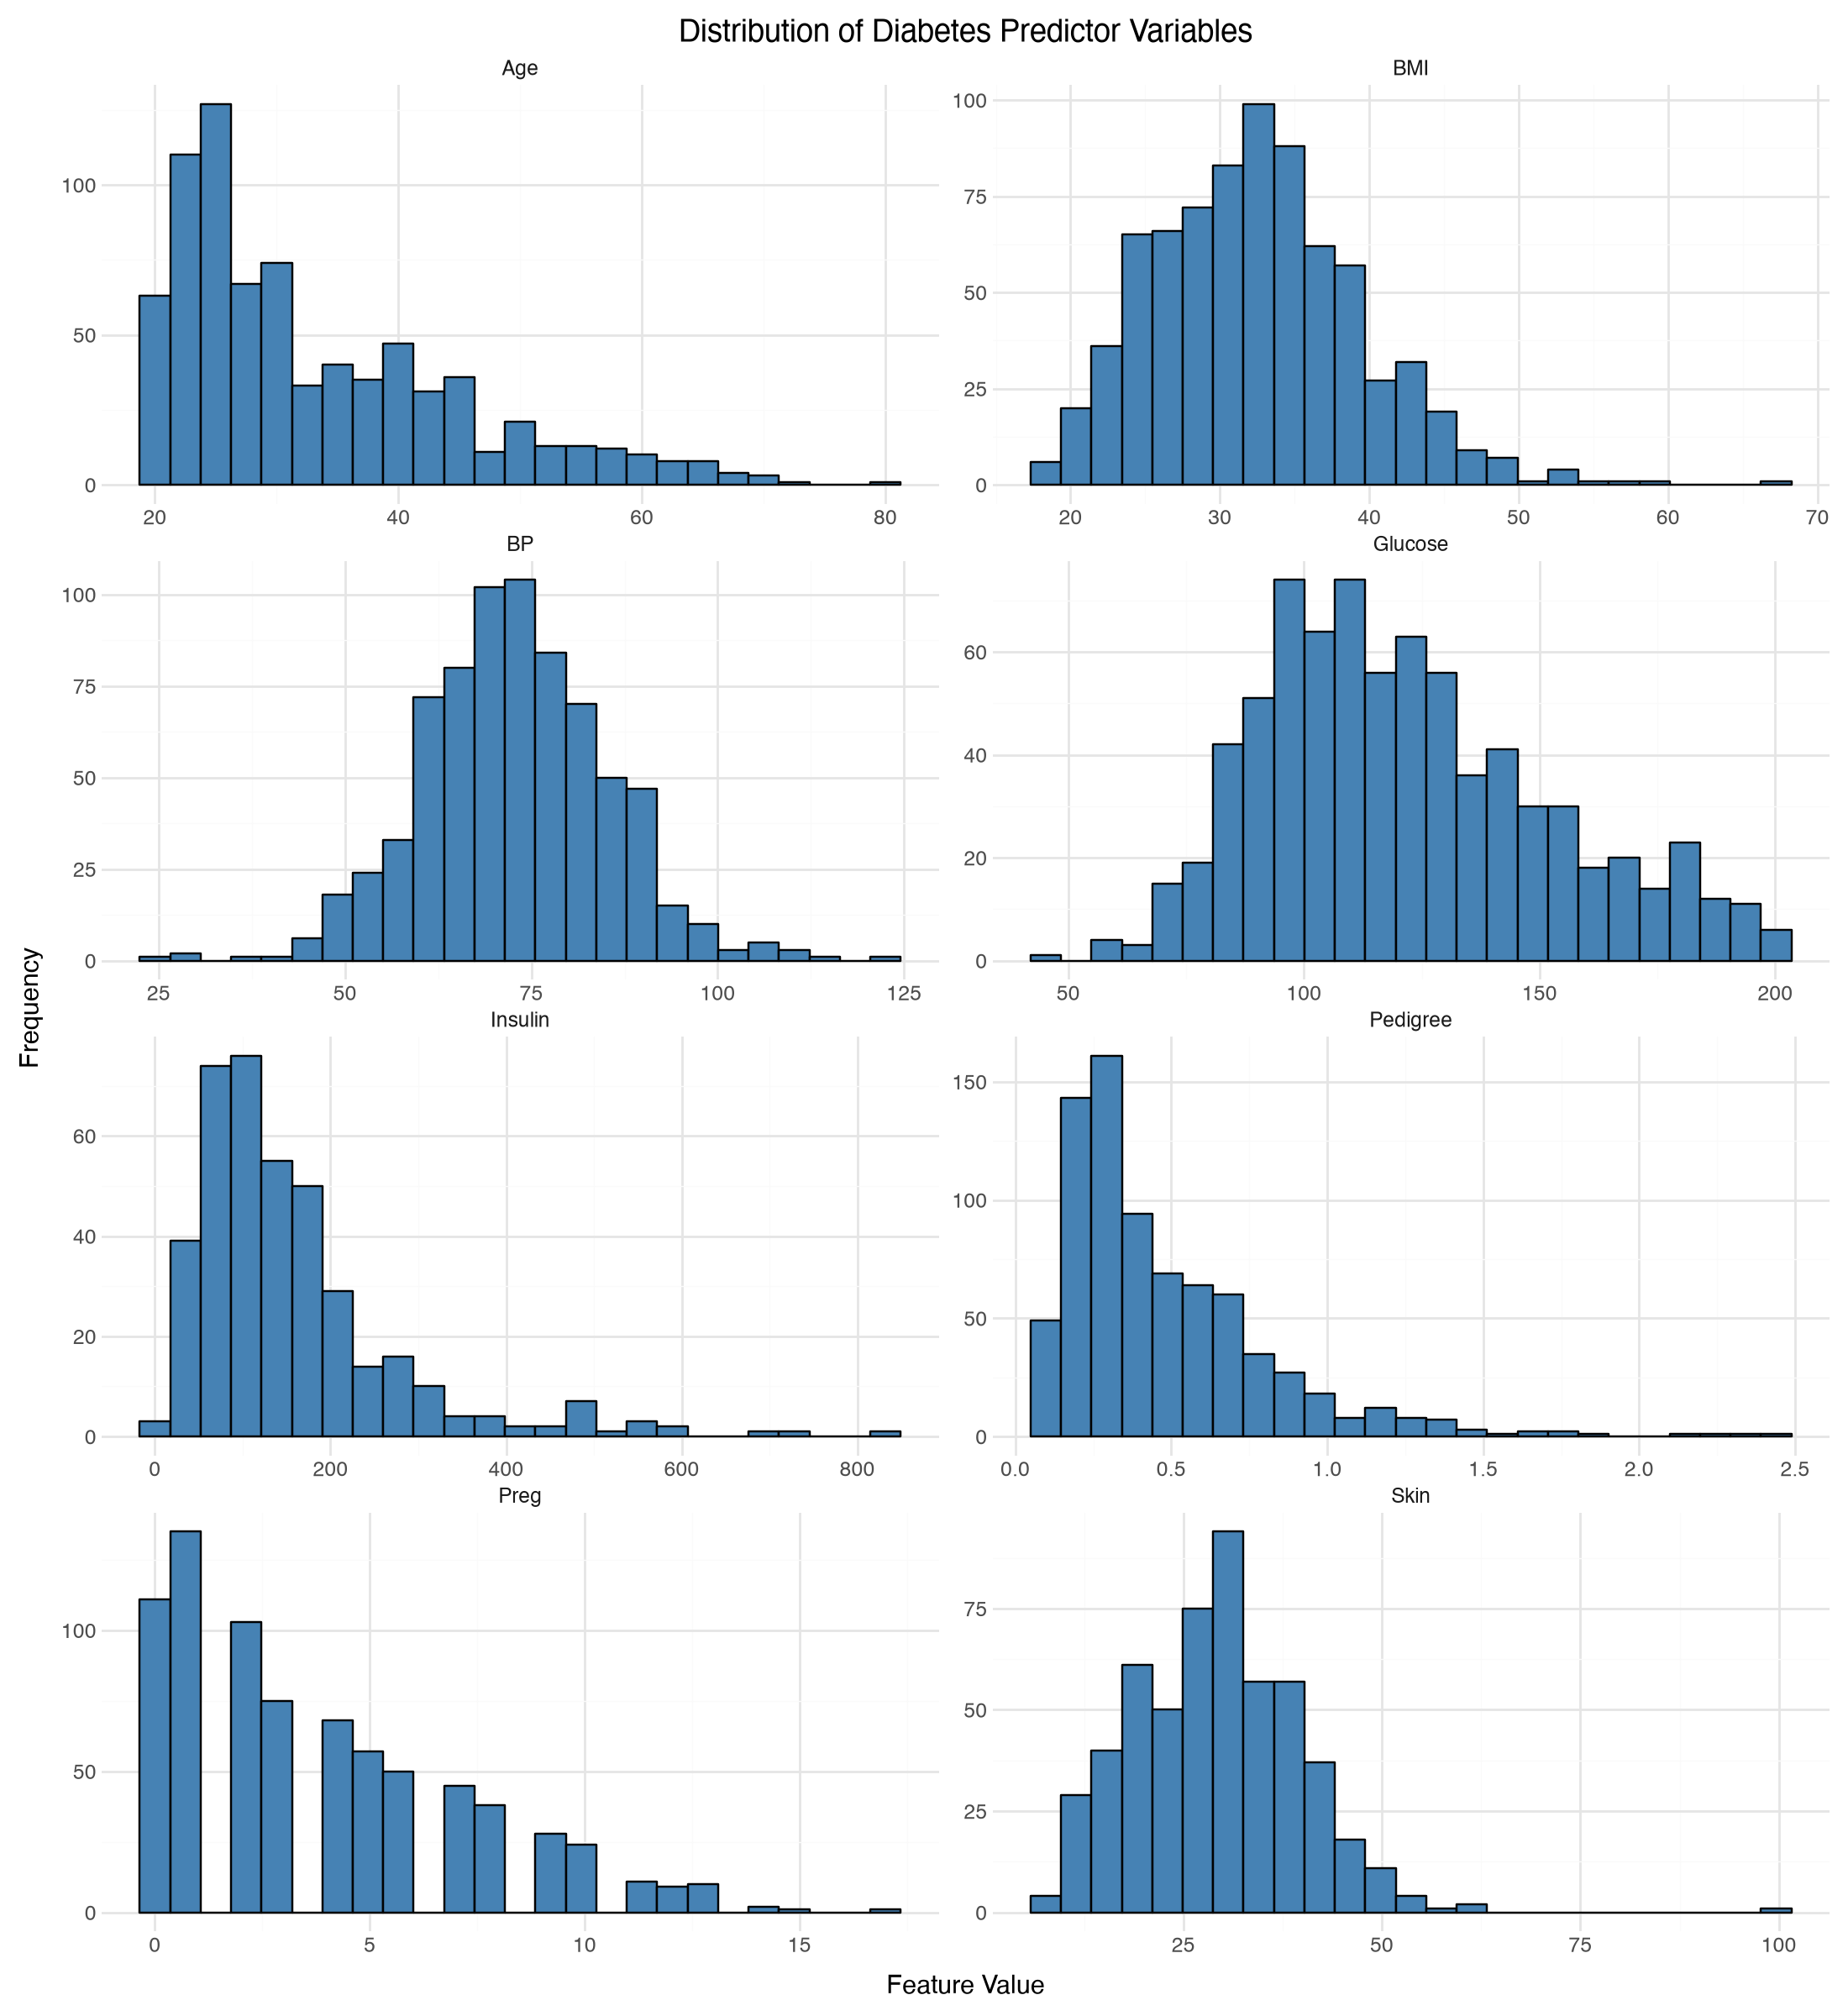

In [17]:
# Returns histograms for all predictor variables in the dataset, showing their distributions
features = [
    "Preg", "Glucose", "BP", "Skin",
    "Insulin", "BMI", "Pedigree", "Age"
]

df_long = df_eda[features].melt(
    var_name="Feature",
    value_name="Value"
)

ggplot(df_long, aes(x="Value")) + \
    geom_histogram(bins=25, fill="steelblue", color="black") + \
    facet_wrap("~Feature", scales="free", ncol=2) + \
    labs(
        title="Distribution of Diabetes Predictor Variables",
        x="Feature Value",
        y="Frequency"
    ) + \
    theme_minimal() + \
    theme(figure_size=(11, 12))

### 6.1 Interpretation

Key Observations:

Glucose: Around 80 to 150 are the most common values. Higher values also exist but are less common. This is slightly right-skewed.

BMI: This is around a normal distribution. Around 25 to 40 are the most common values. There are also some unusually high values that could be considered outliers.

Insulin: This is strongly right-skewed. Many valid values are low, but there are a few that are extremely high.

Age: This is right-skewed. Many values are around 20 to 35 years old, and there are less older values.

Blood Pressure (BP): This is roughly bell-shaped. Around 60–85 are the most common values.

Skin Thickness: Many valid values are around 20 to 40, but there are also some that are unusually high.

Pregnancies (Preg): This is right-skewed. Many values report fewer than five pregnancies.

Diabetes Pedigree Function (Pedigree): Similar to the other right-skewed variable, this is strongly right-skewed. Many are low, but there are a few that are unusually high.

Preprocessing Implications:

Because of this data’s skewness and the possible outliers, some preprocessing could be needed to adjust these variables. Variables that are strongly right-skewed include insulin and pedigree. Those that are near normal include blood pressure and BMI.

Because some data points could be genuinely about the individuals, rather than being errors, it would be important to examine rather than delete any outliers.

This will influence how missing values are imputed, if any transformation is needed, and how the data should be scaled during preprocessing.